# 06 — EDA de columnas nuevas (category_id, fechas, precio)

Explora tres grupos de columnas que todavía no entraron a ningún `Pipeline`: `category_id`, las columnas de fecha, y la relación `price`/`base_price`. Para cada grupo: primero existencia/tipo/nulos en train y test, después relación con `condition` (`new`/`used`) usando **solo train** (acá no se mide CV todavía, eso es el paso siguiente en `07_nuevas_features.ipynb`).

No toca `01_eda.ipynb`.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_json("../data/train_data.jsonlines", lines=True)
test = pd.read_json("../data/test_data.jsonlines", lines=True)

print("train:", train.shape, "| test:", test.shape)
print("condition en train:", "condition" in train.columns, "| en test:", "condition" in test.columns)

train: (70000, 45) | test: (30000, 44)
condition en train: True | en test: False


## Grupo A — `category_id`

`category_id` (ej. `MLA73721`) es la categoría de MercadoLibre de la publicación (no confundir con `listing_type_id`, que es el tipo de publicación). Confirmado arriba: existe en train y test, sin nulos, tipo string.

categorías únicas en train: 9570
categorías únicas en test: 6675
categorías de test que aparecen en train: 5338 (94.7% de las filas de test)

Publicaciones por categoría (train):
count    9570.000000
mean        7.314525
std        40.702748
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max      3180.000000
dtype: float64


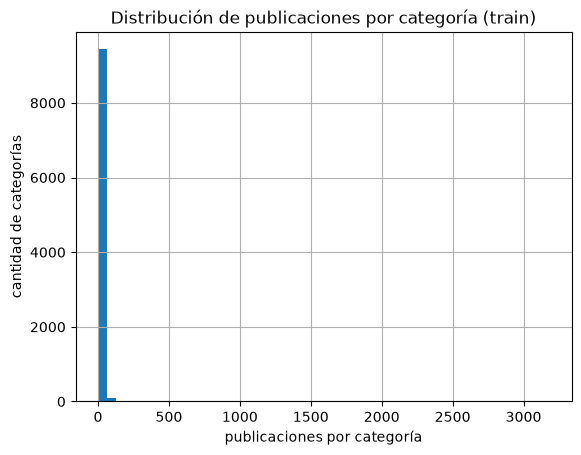

In [2]:
categorias_train = set(train["category_id"])
categorias_test = set(test["category_id"])
compartidas = categorias_train & categorias_test

print("categorías únicas en train:", train["category_id"].nunique())
print("categorías únicas en test:", test["category_id"].nunique())
print("categorías de test que aparecen en train:", len(compartidas),
      f"({100 * test['category_id'].isin(compartidas).mean():.1f}% de las filas de test)")

publicaciones_por_categoria = train.groupby("category_id").size()
print("\nPublicaciones por categoría (train):")
print(publicaciones_por_categoria.describe())

publicaciones_por_categoria.hist(bins=50)
plt.xlabel("publicaciones por categoría")
plt.ylabel("cantidad de categorías")
plt.title("Distribución de publicaciones por categoría (train)")
plt.show()

In [3]:
es_new = (train["condition"] == "new").astype(int)
resumen_categoria = pd.DataFrame({
    "n_publicaciones": train.groupby("category_id").size(),
    "pct_new": es_new.groupby(train["category_id"]).mean(),
})

pocas_publicaciones = (resumen_categoria["n_publicaciones"] <= 5).sum()
print(f"Categorías con 5 o menos publicaciones: {pocas_publicaciones} de {len(resumen_categoria)} "
      f"({100*pocas_publicaciones/len(resumen_categoria):.1f}%)")

con_volumen = resumen_categoria[resumen_categoria["n_publicaciones"] >= 20]
print(f"\nCategorías con 20+ publicaciones: {len(con_volumen)}")

print("\nTop 10 más 'nuevas' (entre las de 20+ publicaciones):")
print(con_volumen.sort_values("pct_new", ascending=False).head(10))

print("\nTop 10 más 'usadas' (entre las de 20+ publicaciones):")
print(con_volumen.sort_values("pct_new", ascending=True).head(10))

Categorías con 5 o menos publicaciones: 7213 de 9570 (75.4%)

Categorías con 20+ publicaciones: 627

Top 10 más 'nuevas' (entre las de 20+ publicaciones):
             n_publicaciones  pct_new
category_id                          
MLA373459                 31      1.0
MLA66314                  21      1.0
MLA45536                  38      1.0
MLA45558                  57      1.0
MLA45559                  26      1.0
MLA4560                   26      1.0
MLA45670                  21      1.0
MLA45679                  21      1.0
MLA46611                  22      1.0
MLA46675                  27      1.0

Top 10 más 'usadas' (entre las de 20+ publicaciones):
             n_publicaciones  pct_new
category_id                          
MLA12205                  56      0.0
MLA47329                  71      0.0
MLA47290                  31      0.0
MLA47280                  24      0.0
MLA87505                  23      0.0
MLA12241                  28      0.0
MLA12242                  27  

**Conclusión Grupo A (confirmado por los datos).** 9.570 categorías en train, muy desparejo: mediana de 2 publicaciones por categoría, pero la más grande tiene 3.180 (típico de e-commerce: pocas categorías gigantes, muchísimas chicas — 75,4% tiene 5 publicaciones o menos). Aun así, el **94,7% de las filas de test** tiene una categoría que ya vimos en train, mucho mejor cobertura que la de vendedor (71,6%).

La señal es muy fuerte: entre las categorías con 20+ publicaciones (627 categorías), varias tienen **100% `new`** (ej. `MLA373459`, 31 publicaciones) o **100% `used`** (ej. `MLA47329`, 71 publicaciones) — categorías enteras dedicadas a un solo tipo de producto (ej. "insumos nuevos de fábrica" vs. "repuestos usados"). Esto hace pensar que un target encoding de `category_id` puede aportar tanto o más que el de vendedor.

**Propuesta concreta:** target encoding de `category_id` (análogo a `seller_pct_new`), con el mismo cuidado de *leave-one-out* — se mide en el Paso 3. Con 75% de las categorías teniendo 5 publicaciones o menos, el *fallback* a un promedio global (o algo de *shrinkage*) va a ser importante para no sobreajustar en categorías chicas — lo reviso en detalle antes de implementarlo, como pediste.

## Grupo B — Fechas (`start_time`, `stop_time`, `date_created`, `last_updated`)

`date_created` y `last_updated` vienen como texto con zona horaria UTC (`...Z`); `start_time`/`stop_time` ya los parseó `pandas` como fecha sin zona. Para poder restar fechas entre sí, primero les saco la zona horaria a los dos primeros (`tz_localize(None)`) — no cambia el instante real, solo el formato, para que todas queden comparables.

Plan: (1) rango de cada fecha en train vs test, (2) duración de la publicación, (3) diferencia entre creación y publicación, (4) mes/día/hora de inicio, (5) qué tan "vieja" es la última actualización respecto del inicio — para cada una, relación con `new`/`used`.

In [4]:
for c in ["date_created", "last_updated"]:
    train[c] = pd.to_datetime(train[c]).dt.tz_localize(None)
    test[c] = pd.to_datetime(test[c]).dt.tz_localize(None)

cols_fecha = ["start_time", "stop_time", "date_created", "last_updated"]
for c in cols_fecha:
    print(f"{c:15} train: {train[c].min()} -> {train[c].max()}")
    print(f"{'':15} test:  {test[c].min()} -> {test[c].max()}")

start_time      train: 2013-05-21 14:50:16 -> 2015-10-15 09:14:30
                test:  2013-05-21 04:22:35 -> 2015-10-15 09:10:37
stop_time       train: 2015-10-14 11:51:37 -> 2024-11-04 14:55:51
                test:  2015-10-14 23:30:00 -> 2024-11-04 14:55:51
date_created    train: 2013-05-21 14:50:17 -> 2015-10-15 09:14:30
                test:  2013-05-21 04:22:35 -> 2015-10-15 09:10:37
last_updated    train: 2014-11-11 20:15:04 -> 2015-10-15 10:48:48.026000
                test:  2014-11-25 04:08:06 -> 2015-10-15 10:18:15.700000


In [5]:
es_new = (train["condition"] == "new").astype(int)

duracion = (train["stop_time"] - train["start_time"]).dt.total_seconds() / 86400
print("Duración de la publicación (días) — describe:")
print(duracion.describe())
print("\nValores más comunes (redondeados a día):")
print(duracion.round().value_counts().head(6))

print("\nDuración promedio/mediana por condition:")
print(pd.DataFrame({"duracion": duracion, "condition": train["condition"]}).groupby("condition")["duracion"].agg(["mean", "median", "std"]))

largas = duracion > 365
print(f"\nPublicaciones con duración > 365 días: {largas.sum()} -> pct_new: {es_new[largas].mean():.3f}")
print(f"Publicaciones con duración <= 365 días: {(~largas).sum()} -> pct_new: {es_new[~largas].mean():.3f}")

Duración de la publicación (días) — describe:
count    70000.000000
mean        60.893760
std         37.818337
min          0.398846
25%         60.000000
50%         60.000000
75%         60.000000
max       3457.052106
dtype: float64

Valores más comunes (redondeados a día):
60.0     67672
7.0        526
30.0       194
61.0       145
62.0        87
365.0       78
Name: count, dtype: int64

Duración promedio/mediana por condition:
                mean  median        std
condition                              
new        61.285137    60.0  48.396082
used       60.439883    60.0  19.294948

Publicaciones con duración > 365 días: 42 -> pct_new: 0.714
Publicaciones con duración <= 365 días: 69958 -> pct_new: 0.537


In [6]:
diff_creacion = (train["start_time"] - train["date_created"]).dt.total_seconds()
casi_simultaneo = diff_creacion.abs() < 1

print("¿La publicación arranca en el mismo instante en que se crea?")
print(f"  Simultánea (<1seg de diferencia): {casi_simultaneo.sum()} ({100*casi_simultaneo.mean():.1f}%) -> pct_new: {es_new[casi_simultaneo].mean():.3f}")
print(f"  Con demora:                        {(~casi_simultaneo).sum()} ({100*(~casi_simultaneo).mean():.1f}%) -> pct_new: {es_new[~casi_simultaneo].mean():.3f}")

¿La publicación arranca en el mismo instante en que se crea?
  Simultánea (<1seg de diferencia): 55789 (79.7%) -> pct_new: 0.535
  Con demora:                        14211 (20.3%) -> pct_new: 0.544


Mes de inicio — pct_new y cantidad de filas:
                mean  count
start_time                 
1           0.222222      9
2           0.620690     29
3           0.363636     22
4           0.571429     28
5           0.375000     48
6           0.549020     51
7           0.500000    192
8           0.530442  15981
9           0.536505  34201
10          0.544559  19390
11          0.375000     24
12          0.320000     25

Día de semana (0=lunes) — pct_new y cantidad de filas:
                mean  count
start_time                 
0           0.548949  12513
1           0.562314  13103
2           0.550085  11191
3           0.521948   8748
4           0.557006  10262
5           0.506221   7394
6           0.466932   6789


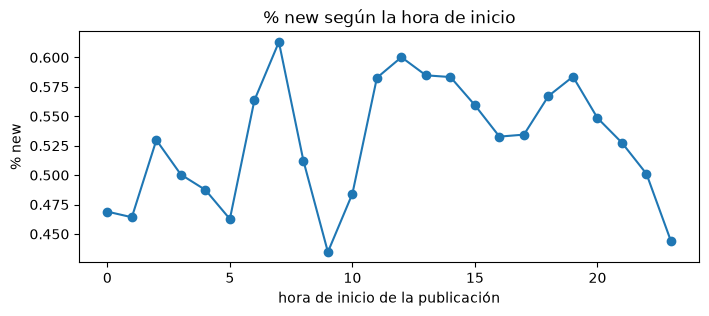

In [7]:
mes = train["start_time"].dt.month
dow = train["start_time"].dt.dayofweek  # 0=lunes
hora = train["start_time"].dt.hour

print("Mes de inicio — pct_new y cantidad de filas:")
print(es_new.groupby(mes).agg(["mean", "count"]))

print("\nDía de semana (0=lunes) — pct_new y cantidad de filas:")
print(es_new.groupby(dow).agg(["mean", "count"]))

fig, ax = plt.subplots(figsize=(8, 3))
es_new.groupby(hora).mean().plot(ax=ax, marker="o")
ax.set_xlabel("hora de inicio de la publicación")
ax.set_ylabel("% new")
ax.set_title("% new según la hora de inicio")
plt.show()

In [8]:
gap_actualizacion = (train["last_updated"] - train["start_time"]).dt.total_seconds() / 86400
print("last_updated - start_time (días) — describe:")
print(gap_actualizacion.describe())

cuartiles = pd.qcut(gap_actualizacion, 4, duplicates="drop")
print("\npct_new por cuartil de ese gap:")
print(es_new.groupby(cuartiles).agg(["mean", "count"]))

last_updated - start_time (días) — describe:
count    70000.000000
mean         7.212433
std         20.603263
min          0.000000
25%          0.000023
50%          0.000058
75%          6.031852
max        848.255752
dtype: float64

pct_new por cuartil de ese gap:
                          mean  count
(-0.001, 2.31e-05]    0.487107  19002
(2.31e-05, 5.79e-05]  0.496314  16280
(5.79e-05, 6.032]     0.500465  17218
(6.032, 848.256]      0.664857  17500


**Conclusión Grupo B (confirmado por los datos, salvo que aclare lo contrario).**

- **Rango train vs test:** ambos van de 2013-05-21 a 2015-10-15 en `start_time`/`date_created` — mismo período, consistente con la referencia inicial. `stop_time` tiene un rango rarísimo (hasta 2024-11-04) porque hay publicaciones con duración "indefinida" que usan una fecha de fin muy lejana como placeholder — no es un dato real de cuándo termina.
- **Duración de la publicación:** **96,7%** de las filas (67.672 de 70.000) dura exactamente **60 días** (la duración estándar de MercadoLibre) — como variable es casi constante, poca varianza para aportar. Las pocas publicaciones con duración > 365 días (42 filas) tienen 71,4% de `new` contra 53,7% del resto, pero la muestra es demasiado chica (42 filas) para confiar en el patrón. **No parece útil como feature dedicada.**
- **Creación vs. inicio:** en el 79,7% de los casos arrancan en el mismo instante. El 20,3% restante que se crea antes de empezar tiene prácticamente el mismo `pct_new` (0,544 vs 0,535) que el resto — **sin señal real**, descarto esta columna.
- **Mes/día/hora de inicio:** el 99,4% de las publicaciones arranca en agosto-octubre (la ventana de scrapeo), así que mes **no sirve** (hay meses con 9-50 filas, puro ruido). Día de la semana está bastante parejo (0,47-0,56). La **hora** sí muestra algo más de variación: mínimos a la madrugada (~0,44-0,49) y picos al mediodía/tarde (~0,58-0,60) — es **suposición, no confirmado del todo**, podría reflejar vendedores profesionales publicando en horario laboral, pero vale la pena medirla con CV.
- **`last_updated` − `start_time` (qué tan "vieja" es la última actualización):** acá sí hay señal clara — el cuartil superior (gap > 6 días) tiene **pct_new = 0,665**, bien por encima de los otros tres cuartiles (~0,49-0,50). Tiene sentido: una tienda que gestiona stock nuevo actualiza la publicación de nuevo seguido; alguien que publica un usado una vez y se olvida, no.

**Propuesta concreta para el Paso 3 (bloque L):** `hora_inicio` (categórica u ordinal) y `gap_actualizacion` (numérica, en días) — las dos con señal real en el EDA. Dejo afuera duración, mes, y la diferencia creación/inicio por falta de señal o muestra insuficiente.

## Grupo C — Precio (`price` vs `base_price`, "redondez")

Plan: (1) ¿`price` y `base_price` son el mismo número casi siempre?, (2) flags de "redondez" (múltiplo de 100/1.000, termina en 9/99, tiene decimales) y su relación con `new`/`used`, (3) lo mismo separado por moneda (`currency_id`: `ARS`/`USD`).

In [12]:
iguales = train["price"] == train["base_price"]
print(f"price == base_price: {iguales.sum()} de {len(train)} ({100*iguales.mean():.2f}%)")

diff = (train["base_price"] - train["price"])[~iguales]
print(f"\nCuando difieren (solo {(~iguales).sum()} filas), diferencia describe:")
print(diff.describe())
print(f"\npct_new cuando son iguales: {es_new[iguales].mean():.3f} (n={iguales.sum()})")
print(f"pct_new cuando difieren:    {es_new[~iguales].mean():.3f} (n={(~iguales).sum()}) <- muestra muy chica, no confiar")

price == base_price: 69982 de 70000 (99.97%)

Cuando difieren (solo 18 filas), diferencia describe:
count      18.000000
mean     -457.694444
std      1537.542205
min     -6584.000000
25%       -45.250000
50%       -31.500000
75%       -15.000000
max        -6.500000
dtype: float64

pct_new cuando son iguales: 0.537 (n=69982)
pct_new cuando difieren:    0.611 (n=18) <- muestra muy chica, no confiar


In [13]:
price = train["price"]

flags_precio = pd.DataFrame({
    "tiene_decimales": price % 1 != 0,
    "mult_100": price % 100 == 0,
    "mult_1000": price % 1000 == 0,
    "termina_9": price.astype("int64") % 10 == 9,
    "termina_99": price.astype("int64") % 100 == 99,
    "currency_id": train["currency_id"],
    "es_new": es_new,
})

for f in ["tiene_decimales", "mult_100", "mult_1000", "termina_9", "termina_99"]:
    pct_filas = 100 * flags_precio[f].mean()
    print(f"{f} (en {pct_filas:.1f}% de las filas):")
    print(flags_precio.groupby(f)["es_new"].agg(["mean", "count"]))
    print()

tiene_decimales (en 13.7% de las filas):
                     mean  count
tiene_decimales                 
False            0.493235  60387
True             0.811713   9613

mult_100 (en 22.1% de las filas):
              mean  count
mult_100                 
False     0.590447  54540
True      0.348318  15460

mult_1000 (en 4.5% de las filas):
               mean  count
mult_1000                 
False      0.550446  66864
True       0.249681   3136

termina_9 (en 14.5% de las filas):
               mean  count
termina_9                 
False      0.497996  59866
True       0.767219  10134

termina_99 (en 5.9% de las filas):
                mean  count
termina_99                 
False       0.524595  65866
True        0.734156   4134



In [14]:
print("Filas por moneda:", flags_precio["currency_id"].value_counts().to_dict())
print()
for moneda in ["ARS", "USD"]:
    sub = flags_precio[flags_precio["currency_id"] == moneda]
    print(f"--- {moneda} (n={len(sub)}) ---")
    for f in ["mult_100", "mult_1000", "termina_9", "termina_99"]:
        print(f" {f}:")
        print(sub.groupby(f)["es_new"].agg(["mean", "count"]).to_string().replace("\n", "\n "))
    print()

Filas por moneda: {'ARS': 69601, 'USD': 399}

--- ARS (n=69601) ---
 mult_100:
              mean  count
 mult_100                 
 False     0.590488  54521
 True      0.347613  15080
 mult_1000:
               mean  count
 mult_1000                 
 False      0.550510  66809
 True       0.235315   2792
 termina_9:
               mean  count
 termina_9                 
 False      0.498781  59467
 True       0.767219  10134
 termina_99:
                mean  count
 termina_99                 
 False       0.525471  65467
 True        0.734156   4134

--- USD (n=399) ---
 mult_100:
              mean  count
 mult_100                 
 False     0.473684     19
 True      0.376316    380
 mult_1000:
               mean  count
 mult_1000                 
 False      0.472727     55
 True       0.366279    344
 termina_9:
               mean  count
 termina_9                 
 False      0.380952    399
 termina_99:
                mean  count
 termina_99                 
 False       

**Conclusión Grupo C (confirmado por los datos) — la señal más fuerte de los tres grupos.**

- **`price` vs `base_price`:** son el mismo número en el **99,97%** de las filas (solo 18 difieren) — no sirve como feature, la muestra donde difieren es demasiado chica para sacar ninguna conclusión.
- **Redondez — señal muy fuerte y con muestras grandes (miles de filas en cada grupo), no es ruido:**

| flag | % de filas | pct_new sin el flag | pct_new con el flag |
|---|---|---|---|
| `tiene_decimales` | 13,7% | 0,493 | **0,812** |
| `termina_9` | 14,5% | 0,498 | **0,767** |
| `termina_99` | 5,9% | 0,525 | **0,734** |
| `mult_100` | 22,1% | 0,590 | **0,348** |
| `mult_1000` | 4,5% | 0,550 | **0,250** |

Interpretación de negocio: un precio con decimales o que termina en 9/99 (ej. `$499`, `$1299.90`) es "precio de catálogo/tienda" — típico de vendedores profesionales que venden `new`. Un precio redondo (`$500`, `$1200`) es lo que escribe alguien vendiendo su propia cosa usada, estimando "más o menos". Es el patrón de *charm pricing* que se usa en retail.

- **Por moneda:** el 99,4% de las filas son `ARS` (69.601) — ahí se repiten los mismos patrones de la tabla de arriba. En `USD` (solo 399 filas, 0,6% del total) el patrón de `mult_100`/`mult_1000` va en la misma dirección pero mucho más débil, y **ninguna fila en USD termina en 9 ni en 99** (son 0 publicaciones con esos flags) — con tan pocos casos, no se puede separar de forma confiable por moneda. Uso los flags calculados sobre el precio tal cual, sin diferenciar por moneda — la inmensa mayoría de la señal viene de `ARS` de todas formas.

**Propuesta concreta para el Paso 3 (bloque M):** las 5 flags de redondez (`tiene_decimales`, `mult_100`, `mult_1000`, `termina_9`, `termina_99`). Descarto la comparación `price` vs `base_price` por falta de muestra.